### SmallTalk 3: Final Evaluation
Runs the fine-tuned models, scores every run the same way, and answers the main question: how much of the gap to the bigger models did agentic RAG, LoRA SFT and DPO close?

### Setup
On Colab, choose **Runtime > Change runtime type > T4 GPU** first. Upload `smalltalk.py`, `config.py` and `requirements.txt` to `MyDrive/smalltalk/` (or keep them next to this notebook in VS Code). This cell also installs the libraries in `requirements.txt`.

In [1]:
import os, sys
os.environ['HF_HUB_DISABLE_XET'] = '1'   # the Xet downloader can hang on Colab, must be set before any Hugging Face import

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK = '/content/drive/MyDrive/smalltalk'  # results are saved on Drive so a disconnect does not lose them
else:
    WORK = os.getcwd()
os.makedirs(WORK, exist_ok=True)
os.chdir(WORK)
sys.path.insert(0, WORK)   # so the notebook can import smalltalk.py and config.py
print('Working folder:', WORK)
for f in ['smalltalk.py', 'config.py', 'requirements.txt']:
    assert os.path.exists(f), f'Put {f} in the working folder first'

%pip install -q -r requirements.txt

Working folder: <project folder>


Note: you may need to restart the kernel to use updated packages.


### Config
All settings (models, hyperparameters, prompts) are in `config.py`. Edit that file, save it, and run this cell again. To change a setting for this notebook only, set it in a cell after this one.

`RUN_ON` sets where the notebook runs: `'local'` (GPU under 12 GB), `'colab'` (T4), `'server'` (remote GPU server) or `'auto'` to detect it. It only changes the batch size and which model sizes run, so the results stay comparable.

`DOWNLOADS` is the one folder that holds everything downloaded: the dataset in `QMSum/` and the base models in `models/`. What is already there is reused, and only what is missing is downloaded.

In [2]:
import json, glob, importlib
import pandas as pd
import config, smalltalk as st
importlib.reload(config); importlib.reload(st)   # picks up edits to config.py without a kernel restart
from config import *                              # every setting lives in config.py

st.set_seed(SEED)
os.makedirs('runs', exist_ok=True); os.makedirs('results', exist_ok=True)

PROFILE = st.run_profile(RUN_ON)
BATCH = PROFILE['batch_size']
# reuses the dataset and models that are already in the folder, downloads what is missing
st.setup_downloads(DOWNLOADS or PROFILE['downloads'])
# only needed if a model asks you to accept its terms on Hugging Face (keep it after setup_downloads)
# from huggingface_hub import login; login()

train_meetings, val_meetings, test_meetings = (st.load_split(s) for s in ['train', 'val', 'test'])
meetings_by_id = {m['id']: m for m in train_meetings + val_meetings + test_meetings}
test_examples = st.test_subset(st.build_examples(test_meetings), N_TEST)
print('Test questions used:', len(test_examples), '| K =', K, '| 4-bit:', LOAD_4BIT)

Running on: local (6.4 GB GPU), batch size 2, models up to 4.5B, training: True
Downloads folder: ~/smalltalk_downloads (918 GB free)
Models already downloaded: BAAI/bge-small-en-v1.5, Qwen/Qwen3-1.7B, Qwen/Qwen3-4B, google/flan-t5-base, mistralai/Ministral-3-3B-Instruct-2512-BF16, roberta-large, vectara/hallucination_evaluation_model


Test questions used: 150 | K = 8 | 4-bit: True


### 1. Run the fine-tuned models
Same test questions, same retriever, same agent as the baselines. Needs a GPU: run Setup and Config, then this section. Finished runs are skipped and an unfinished one continues, so after a disconnect run it again. Sections 2 to 8 only score the saved answers and can run in a later session.

In [3]:
# run this cell again after a disconnect: finished runs are skipped and unfinished ones continue
retriever = st.Retriever()
for key, model_id in SMALL_MODELS.items():
    for stage in ['sft', 'dpo']:
        adapter = f'adapters/{key}_{stage}'
        if not st.has_adapter(adapter):
            print('Skipping, no adapter yet:', adapter); continue
        paths = {mode: f'runs/{key}_{stage}_{mode}.jsonl' for mode in ['rag', 'agent']}
        todo = [mode for mode, p in paths.items() if st.count_todo(p, test_examples)]
        if not todo:
            print(f'{key}_{stage}: all runs finished, skipped'); continue
        llm = st.LLM(model_id, adapter=adapter, load_4bit=LOAD_4BIT)
        for mode in todo:
            st.run_experiment(llm, mode, test_examples, meetings_by_id, retriever, paths[mode], k=K, batch_size=BATCH)
        llm.unload()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

qwen3_17b_sft: all runs finished, skipped
qwen3_17b_dpo: all runs finished, skipped


### 2. Score every run
- **ROUGE-1/2/L**: word overlap with the human summary
- **BERTScore**: meaning overlap with the human summary
- **Faithfulness** (HHEM-2.1-Open): is the summary supported by the text the model read? A score under 0.5 counts as a hallucination
- **Tool use rate / tool calls / format errors**: how the agent behaved

In [4]:
faith = st.Faithfulness()
results = []
for path in sorted(glob.glob('runs/*.jsonl')):
    key, stage, mode = st.parse_run_name(os.path.basename(path)[:-6])
    results.append({'model': key, 'stage': stage, 'mode': mode, **st.evaluate_run(path, faith)})
res = pd.DataFrame(results).drop(columns='run')
res.to_csv('results/all_results.csv', index=False)
res.round(3)

[transformers] You are using a model of type `HHEMv2Config` to instantiate a model of type `HHEMv2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/113 [00:00<?, ?it/s]

Faithfulness scorer: hhem


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


~/smalltalk_env/lib/python3.12/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


... (24 outputs left out)

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,model,stage,mode,n,rouge1,rouge2,rougeL,bertscore,faithfulness,hallucination_rate,avg_words,loop_rate,sec_per_question,run_minutes,gpu,tokens_per_question,gflops_per_question,tool_use_rate,avg_tool_calls,format_error_rate
0,ministral3_3b,base,agent,150,0.268,0.056,0.152,0.073,0.293,0.827,125.753,0.000,21.135,52.839,local GPU,9079.333,61739.467,0.947,1.767,0.187
1,ministral3_3b,base,rag,150,0.311,0.071,0.177,0.128,0.366,0.713,128.233,0.000,5.358,13.396,local GPU,2296.827,15618.421,NaN,NaN,NaN
2,qwen3_17b,base,agent,150,0.331,0.086,0.202,0.227,0.702,0.247,85.873,0.007,9.594,23.986,local GPU,2594.147,8820.099,0.020,0.040,0.060
3,qwen3_17b,base,rag,150,0.335,0.084,0.203,0.232,0.727,0.233,82.547,0.000,3.285,8.212,local GPU,2184.133,7426.053,NaN,NaN,NaN
4,qwen3_17b,base,zeroshot,150,0.318,0.078,0.196,0.213,NaN,NaN,92.867,0.000,6.944,17.361,local GPU,5927.800,20154.520,NaN,NaN,NaN
5,qwen3_17b,dpo,agent,150,0.350,0.132,0.245,0.242,0.858,0.100,63.273,0.093,9.338,23.345,local GPU,2995.607,10185.063,0.227,0.227,0.000
6,qwen3_17b,dpo,rag,150,0.365,0.139,0.254,0.260,0.879,0.060,60.553,0.047,4.913,12.282,local GPU,2157.040,7333.936,NaN,NaN,NaN
7,qwen3_17b,sft,agent,150,0.300,0.105,0.224,0.173,0.702,0.240,90.287,0.400,12.058,30.144,local GPU,2896.293,9847.397,0.180,0.180,0.000
8,qwen3_17b,sft,rag,150,0.329,0.116,0.242,0.232,0.654,0.313,63.927,0.260,5.088,12.720,local GPU,2162.307,7351.843,NaN,NaN,NaN
9,qwen3_4b,base,agent,150,0.349,0.094,0.211,0.248,0.726,0.207,83.827,0.000,NaN,NaN,NaN,NaN,NaN,0.020,0.033,0.027


#### Time, memory and compute
Time and GPU memory are measured. FLOPs are estimated from the tokens that went through each model: 2 x parameters x tokens to answer, 6 x for SFT with LoRA and 8 x for DPO (Kaplan et al. 2020). Times are only comparable on the same GPU, shown in the `gpu` column. Runs made on another GPU before timing was added use the timing sample from notebook 1, part 4f.

In [5]:
# answering cost per run: seconds, tokens and estimated GFLOPs per question, peak GPU memory of the run
cols = ['model', 'stage', 'mode', 'sec_per_question', 'run_minutes', 'tokens_per_question', 'gflops_per_question', 'gpu']
cost = res.reindex(columns=cols).copy()
cost['gpu'] = cost['gpu'].astype(object)
for path in glob.glob('results/time_samples/*.jsonl'):
    key, stage, mode = st.parse_run_name(os.path.basename(path)[:-6])
    ev = st.evaluate_run(path, use_bertscore=False)
    row = (cost['model'] == key) & (cost['stage'] == stage) & (cost['mode'] == mode) & cost['sec_per_question'].isna()
    for c in ['sec_per_question', 'tokens_per_question', 'gflops_per_question']:
        cost.loc[row, c] = ev[c]
    cost.loc[row, 'run_minutes'] = ev['sec_per_question'] * len(test_examples) / 60
    cost.loc[row, 'gpu'] = ev['gpu'] + ' (timing sample)'

timings = pd.read_csv('results/timings.csv') if os.path.exists('results/timings.csv') else pd.DataFrame(columns=st.TIMING_FIELDS)
answer = timings[timings['step'].astype(str).str.startswith('answer_')]
peak = answer.groupby('model')['peak_gb'].max()   # the model column holds the run name for answering steps
cost['peak_gb'] = [peak.get(f'{m}_{s}_{d}', float('nan')) for m, s, d in zip(cost['model'], cost['stage'], cost['mode'])]
cost.to_csv('results/cost_runs.csv', index=False)
cost.round(2)

,model,stage,mode,sec_per_question,run_minutes,tokens_per_question,gflops_per_question,gpu,peak_gb
0,ministral3_3b,base,agent,21.14,52.84,9079.33,61739.47,local GPU,3.66
1,ministral3_3b,base,rag,5.36,13.40,2296.83,15618.42,local GPU,3.67
2,qwen3_17b,base,agent,9.59,23.99,2594.15,8820.10,local GPU,2.41
3,qwen3_17b,base,rag,3.28,8.21,2184.13,7426.05,local GPU,2.36
4,qwen3_17b,base,zeroshot,6.94,17.36,5927.80,20154.52,local GPU,2.62
5,qwen3_17b,dpo,agent,9.34,23.35,2995.61,10185.06,local GPU,2.37
6,qwen3_17b,dpo,rag,4.91,12.28,2157.04,7333.94,local GPU,2.67
7,qwen3_17b,sft,agent,12.06,30.14,2896.29,9847.40,local GPU,2.37
8,qwen3_17b,sft,rag,5.09,12.72,2162.31,7351.84,local GPU,2.67
9,qwen3_4b,base,agent,7.89,19.73,2426.00,19408.00,local GPU (timing sample),3.65


In [6]:
# training and data steps: a step resumed over several sessions is added up
steps = timings[~timings['step'].astype(str).str.startswith('answer_')]
steps = steps.groupby(['model', 'step', 'gpu'], as_index=False).agg(
    minutes=('seconds', lambda s: s.sum() / 60), sessions=('seconds', 'size'),
    peak_gb=('peak_gb', 'max'), tokens=('tokens', 'sum'), tflops=('tflops', 'sum'))
order = ['sft_data', 'sft_train', 'dpo_candidates', 'dpo_train']
steps = steps.sort_values('step', key=lambda s: s.map({k: i for i, k in enumerate(order)}))
steps.to_csv('results/cost_steps.csv', index=False)
steps.round(2)

,model,step,gpu,minutes,sessions,peak_gb,tokens,tflops
2,qwen3_17b,sft_data,local GPU,1.06,1,0.36,0,0.0
3,qwen3_17b,sft_train,local GPU,33.34,1,2.27,2318119,23644.8
0,qwen3_17b,dpo_candidates,local GPU,90.83,2,3.39,2440654,8298.2
1,qwen3_17b,dpo_train,local GPU,25.62,1,2.85,1048684,14262.1


### 3. Did the small model close the gap?
`gap closed = (tuned small - base small) / (bigger model - base small)`. 0 means no progress, 1 means the small model matched the bigger model, above 1 means it beat it. Agentic RAG is the main setting. This only makes sense when the bigger model scores higher than the base small model; if not, read the raw scores instead. Qwen3-8B is included as an extra reference.

In [7]:
def score(model, stage, mode, metric):
    r = res[(res['model'] == model) & (res['stage'] == stage) & (res['mode'] == mode)]
    return float(r[metric].iloc[0]) if len(r) else float('nan')

MODE = GAP_MODE   # set in config.py
rows = []
for small, big in FAMILY.items():
    for rival in [big, CROSS_FAMILY] + REFERENCE:
        for metric in ['faithfulness', 'rougeL', 'bertscore']:
            base, sft, dpo, top = (score(small, 'base', MODE, metric), score(small, 'sft', MODE, metric),
                                   score(small, 'dpo', MODE, metric), score(rival, 'base', MODE, metric))
            rows.append({'small model': small, 'compared with': rival, 'metric': metric, 'base small': base,
                         '+SFT': sft, '+SFT+DPO': dpo, 'bigger model': top,
                         'gap closed (SFT)': st.gap_closed(base, sft, top), 'gap closed (DPO)': st.gap_closed(base, dpo, top)})
gap = pd.DataFrame(rows)
gap.to_csv('results/gap_closed.csv', index=False)
gap.round(3)

,small model,compared with,metric,base small,+SFT,+SFT+DPO,bigger model,gap closed (SFT),gap closed (DPO)
0,qwen3_17b,qwen3_4b,faithfulness,0.702,0.702,0.858,0.726,-0.001,6.695
1,qwen3_17b,qwen3_4b,rougeL,0.202,0.224,0.245,0.211,2.405,4.640
2,qwen3_17b,qwen3_4b,bertscore,0.227,0.173,0.242,0.248,-2.671,0.751
3,qwen3_17b,ministral3_3b,faithfulness,0.702,0.702,0.858,0.293,0.000,-0.381
4,qwen3_17b,ministral3_3b,rougeL,0.202,0.224,0.245,0.152,-0.454,-0.877
5,qwen3_17b,ministral3_3b,bertscore,0.227,0.173,0.242,0.073,0.353,-0.099
6,qwen3_17b,qwen3_8b,faithfulness,0.702,0.702,0.858,0.722,-0.002,7.970
7,qwen3_17b,qwen3_8b,rougeL,0.202,0.224,0.245,0.214,1.808,3.490
8,qwen3_17b,qwen3_8b,bertscore,0.227,0.173,0.242,0.243,-3.347,0.941


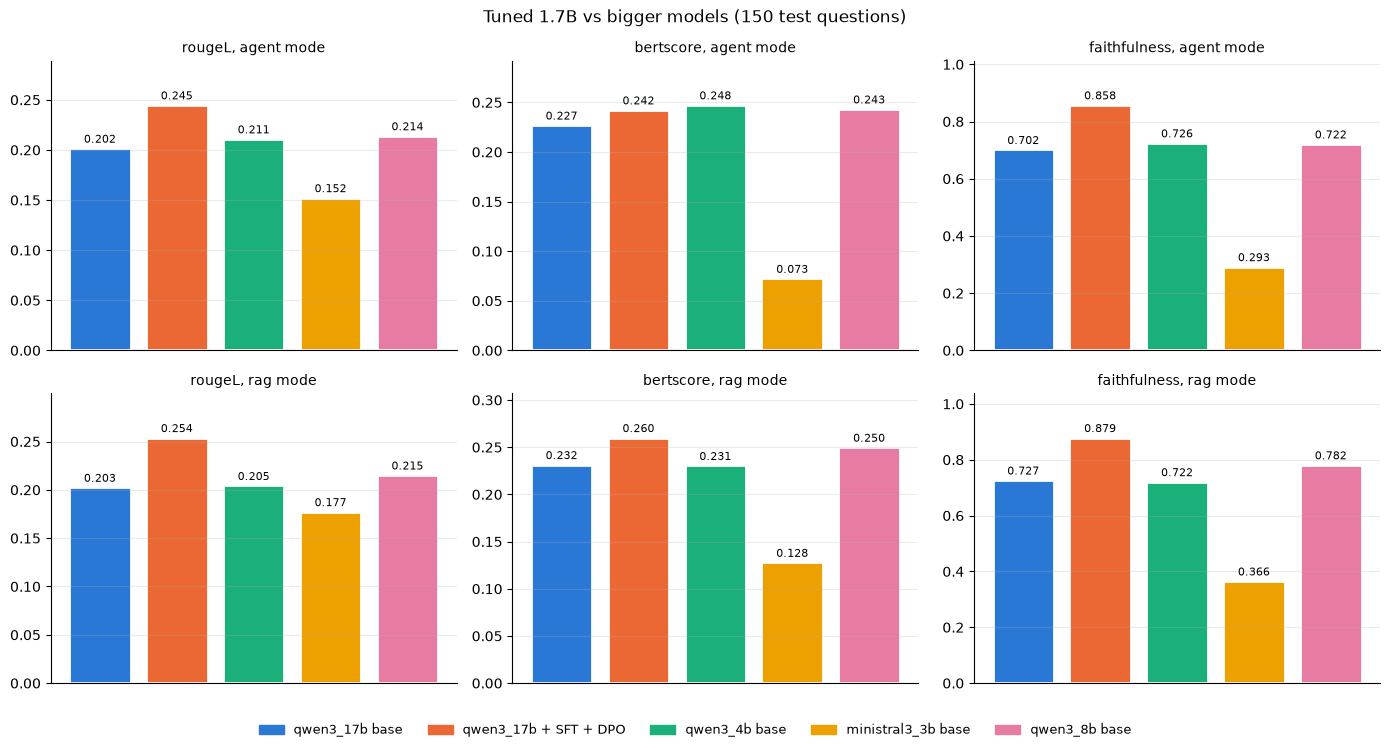

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# every model in rag and agent mode: base small, tuned small (SFT + DPO), then each bigger model
bars = [(s, 'base', f'{s} base') for s in SMALL_MODELS] + [(s, 'dpo', f'{s} + SFT + DPO') for s in SMALL_MODELS]
bars += [(b, 'base', f'{b} base') for b in dict.fromkeys(list(FAMILY.values()) + [CROSS_FAMILY] + REFERENCE)]
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']   # fixed order
metrics, modes = ['rougeL', 'bertscore', 'faithfulness'], ['agent', 'rag']
fig, axes = plt.subplots(len(modes), len(metrics), figsize=(14, 7.5), squeeze=False)
x = np.arange(len(bars))
for row, mode in zip(axes, modes):
    for ax, metric in zip(row, metrics):
        vals = [score(m, stage, mode, metric) for m, stage, _ in bars]
        b = ax.bar(x, vals, width=0.8, color=colors[:len(bars)], edgecolor='white', linewidth=2)
        ax.bar_label(b, fmt='%.3f', fontsize=8, padding=2)   # values on the bars, colour is not the only cue
        ax.set_title(f'{metric}, {mode} mode', fontsize=10); ax.set_xticks([])
        ax.set_ylim(0, max(v for v in vals if v == v) * 1.18)
        ax.grid(axis='y', alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors[:len(bars)]]
fig.legend(handles, [label for *_, label in bars], loc='lower center', ncol=len(bars), frameon=False, fontsize=9)
fig.suptitle('Tuned 1.7B vs bigger models (150 test questions)')
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.savefig('results/main_chart.png', dpi=200); plt.show()


Are the differences real? Each difference gets a 95% interval from a paired bootstrap over the same questions. `difference` = tuned small model minus the other model, and `real_difference` is True when the interval does not include 0.

In [9]:
sig = []
for small, big in FAMILY.items():
    tuned = f'runs/{small}_dpo_{MODE}.jsonl'
    for other in [f'{small}_base', f'{small}_sft', f'{big}_base', f'{CROSS_FAMILY}_base'] + [f'{r}_base' for r in REFERENCE]:
        path = f'runs/{other}_{MODE}.jsonl'
        if os.path.exists(tuned) and os.path.exists(path):
            sig += [{'tuned small vs': other, **row} for row in st.compare_runs(path, tuned, faith)]
sig = pd.DataFrame(sig)
sig.to_csv('results/significance.csv', index=False)
sig.round(3)

,tuned small vs,metric,n,difference,ci_low,ci_high,real_difference,b_better_share
0,qwen3_17b_base,rougeL,150,0.043,0.028,0.060,True,0.660
1,qwen3_17b_base,faithfulness,150,0.156,0.109,0.203,True,0.793
2,qwen3_17b_sft,rougeL,150,0.021,0.005,0.039,True,0.533
3,qwen3_17b_sft,faithfulness,150,0.156,0.110,0.204,True,0.747
4,qwen3_4b_base,rougeL,150,0.034,0.019,0.051,True,0.573
5,qwen3_4b_base,faithfulness,150,0.133,0.080,0.186,True,0.713
6,ministral3_3b_base,rougeL,150,0.093,0.075,0.113,True,0.847
7,ministral3_3b_base,faithfulness,150,0.566,0.518,0.610,True,0.967
8,qwen3_8b_base,rougeL,150,0.031,0.015,0.048,True,0.593
9,qwen3_8b_base,faithfulness,150,0.137,0.082,0.188,True,0.707


### 4. What did each step add?
Ablation for each small model: zero-shot, standard RAG, agentic RAG, then fine-tuning.

In [10]:
order = [('base', 'zeroshot'), ('base', 'rag'), ('base', 'agent'), ('sft', 'rag'), ('sft', 'agent'), ('dpo', 'rag'), ('dpo', 'agent')]
abl = []
for small in SMALL_MODELS:
    for stage, mode in order:
        r = res[(res['model'] == small) & (res['stage'] == stage) & (res['mode'] == mode)]
        if len(r):
            abl.append({'model': small, 'setup': f'{stage} + {mode}',
                        **r[['rougeL', 'bertscore', 'faithfulness', 'hallucination_rate', 'loop_rate', 'avg_words']].iloc[0].to_dict()})
abl = pd.DataFrame(abl)
abl.to_csv('results/ablation.csv', index=False)
abl.round(3)


,model,setup,rougeL,bertscore,faithfulness,hallucination_rate,loop_rate,avg_words
0,qwen3_17b,base + zeroshot,0.196,0.213,NaN,NaN,0.000,92.867
1,qwen3_17b,base + rag,0.203,0.232,0.727,0.233,0.000,82.547
2,qwen3_17b,base + agent,0.202,0.227,0.702,0.247,0.007,85.873
3,qwen3_17b,sft + rag,0.242,0.232,0.654,0.313,0.260,63.927
4,qwen3_17b,sft + agent,0.224,0.173,0.702,0.240,0.400,90.287
5,qwen3_17b,dpo + rag,0.254,0.260,0.879,0.060,0.047,60.553
6,qwen3_17b,dpo + agent,0.245,0.242,0.858,0.100,0.093,63.273


### 5. General vs specific questions

In [11]:
def by_qtype(path):
    rows = st.read_jsonl(path)
    out = {}
    for qtype in ['general', 'specific']:
        sub = [r for r in rows if r['qtype'] == qtype]
        if sub:
            out[f'rougeL_{qtype}'] = st.rouge([r['pred'] for r in sub], [r['answer'] for r in sub])['rougeL']
    return out

qtypes = pd.DataFrame([{'run': os.path.basename(p)[:-6], **by_qtype(p)} for p in sorted(glob.glob('runs/*_agent.jsonl'))])
qtypes.to_csv('results/question_types.csv', index=False)
qtypes.round(3)

,run,rougeL_general,rougeL_specific
0,ministral3_3b_base_agent,0.159,0.151
1,qwen3_17b_base_agent,0.210,0.201
2,qwen3_17b_dpo_agent,0.227,0.248
3,qwen3_17b_sft_agent,0.182,0.231
4,qwen3_4b_base_agent,0.209,0.211
5,qwen3_8b_base_agent,0.224,0.213


### 6. Agent behaviour
Which tools each model used. Fine-tuning on plain RAG prompts can make a model worse at following the agent format, so check the format error rate here.

In [12]:
from collections import Counter
usage = []
for path in sorted(glob.glob('runs/*_agent.jsonl')):
    rows = st.read_jsonl(path)
    c = Counter(step['tool'] for r in rows for step in r['trace'])
    usage.append({'run': os.path.basename(path)[:-6], **{t: round(n / len(rows), 2) for t, n in c.items()},
                  'format_error_rate': round(sum(r['format_errors'] > 0 for r in rows) / len(rows), 2)})
usage = pd.DataFrame(usage).fillna(0)
usage.to_csv('results/tool_usage.csv', index=False)
usage


,run,list_topics,get_topic_segment,get_speaker_turns,search_transcript,tool_name,format_error_rate
0,ministral3_3b_base_agent,0.16,0.28,0.31,1.01,0.01,0.19
1,qwen3_17b_base_agent,0.00,0.00,0.00,0.04,0.00,0.06
2,qwen3_17b_dpo_agent,0.00,0.00,0.00,0.23,0.00,0.00
3,qwen3_17b_sft_agent,0.00,0.00,0.00,0.18,0.00,0.00
4,qwen3_4b_base_agent,0.01,0.01,0.00,0.01,0.00,0.03
5,qwen3_8b_base_agent,0.22,0.43,0.15,0.40,0.00,0.33


### 7. Did the tools help?
The agent starts with the same chunks as standard RAG and chooses whether to call tools. So for each question we can compare the agent answer with the plain RAG answer from the same model.
- **used tools**: questions where the agent chose to read more. A positive `difference` means the extra reading gave a better summary.
- **no tools**: questions where it answered right away. The two answers should score about the same here.

In [13]:
benefit = []
for path in sorted(glob.glob('runs/*_agent.jsonl')):
    rag_path = path.replace('_agent.jsonl', '_rag.jsonl')
    if os.path.exists(rag_path):
        benefit += [{'run': os.path.basename(path)[:-6], **row} for row in st.tool_benefit(path, rag_path)]
benefit = pd.DataFrame(benefit)
benefit.to_csv('results/tool_benefit.csv', index=False)
benefit.round(3)

,run,group,n,rougeL_agent,rougeL_rag,difference,agent_better_share
0,ministral3_3b_base_agent,used tools,142,0.152,0.179,-0.027,0.261
1,ministral3_3b_base_agent,no tools,8,0.155,0.154,0.001,0.375
2,qwen3_17b_base_agent,used tools,3,0.178,0.280,-0.102,0.000
3,qwen3_17b_base_agent,no tools,147,0.202,0.201,0.001,0.490
4,qwen3_17b_dpo_agent,used tools,34,0.268,0.292,-0.025,0.441
5,qwen3_17b_dpo_agent,no tools,116,0.238,0.243,-0.004,0.397
6,qwen3_17b_sft_agent,used tools,27,0.224,0.305,-0.081,0.222
7,qwen3_17b_sft_agent,no tools,123,0.224,0.228,-0.004,0.480
8,qwen3_4b_base_agent,used tools,3,0.229,0.256,-0.028,0.333
9,qwen3_4b_base_agent,no tools,147,0.211,0.203,0.007,0.592


Did it know when to use a tool? For specific questions we know if the starting chunks already held the gold evidence. A model with good judgment uses tools more often when the evidence was missed.

In [14]:
decisions = pd.DataFrame([{'run': os.path.basename(p)[:-6], **row}
                          for p in sorted(glob.glob('runs/*_agent.jsonl')) for row in st.tool_decisions(p)])
decisions.to_csv('results/tool_decisions.csv', index=False)
decisions.round(3)

,run,group,n,tool_use_rate
0,ministral3_3b_base_agent,start had the evidence,119,0.958
1,ministral3_3b_base_agent,start missed the evidence,11,0.909
2,qwen3_17b_base_agent,start had the evidence,119,0.008
3,qwen3_17b_base_agent,start missed the evidence,11,0.091
4,qwen3_17b_dpo_agent,start had the evidence,119,0.185
5,qwen3_17b_dpo_agent,start missed the evidence,11,0.636
6,qwen3_17b_sft_agent,start had the evidence,119,0.143
7,qwen3_17b_sft_agent,start missed the evidence,11,0.636
8,qwen3_4b_base_agent,start had the evidence,119,0.017
9,qwen3_4b_base_agent,start missed the evidence,11,0.000


### 8. DPO attempts
DPO was trained three times (see `report_notes.md`). The first attempt changed the model too little and was stopped before its test answers. The second fixed the repetition loops but made answers half the human length. The third added a length term to the reward and the SFT loss on the chosen summary. The earlier answers are kept in `runs/old/`.

In [15]:
attempts = {'SFT only': ('runs', 'sft'), '2nd DPO (no length control)': ('runs/old/dpo_second_try', 'dpo'),
            '3rd DPO (final)': ('runs', 'dpo')}
cols = ['rouge1', 'rougeL', 'bertscore', 'faithfulness', 'hallucination_rate', 'loop_rate', 'avg_words']
dpo_rows = []
for name, (folder, stage) in attempts.items():
    for mode in ['rag', 'agent']:
        path = f'{folder}/{MODEL_KEY}_{stage}_{mode}.jsonl'
        if os.path.exists(path):
            ev = st.evaluate_run(path, faith)
            dpo_rows.append({'attempt': name, 'mode': mode, **{c: ev[c] for c in cols}})
dpo_attempts = pd.DataFrame(dpo_rows)
dpo_attempts.to_csv('results/dpo_attempts.csv', index=False)
dpo_attempts.round(3)

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (3 outputs left out)

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: roberta-large
Key                       | Status     | 
--------------------------+------------+-
lm_head.dense.bias        | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


,attempt,mode,rouge1,rougeL,bertscore,faithfulness,hallucination_rate,loop_rate,avg_words
0,SFT only,rag,0.329,0.242,0.232,0.654,0.313,0.260,63.927
1,SFT only,agent,0.300,0.224,0.173,0.702,0.240,0.400,90.287
2,2nd DPO (no length control),rag,0.300,0.217,0.258,0.869,0.087,0.007,32.347
3,2nd DPO (no length control),agent,0.314,0.224,0.237,0.852,0.127,0.073,46.173
4,3rd DPO (final),rag,0.365,0.254,0.260,0.879,0.060,0.047,60.553
5,3rd DPO (final),agent,0.350,0.245,0.242,0.858,0.100,0.093,63.273


### 9. Error analysis
The final model's least faithful summaries, to see what kind of mistakes are left.

In [16]:
FINAL = FINAL_RUN   # set in config.py
rows = st.read_jsonl(FINAL)
scores = st.faith_scores(FINAL, faith)   # saved by the scoring cell above
for i in np.argsort(scores)[:3]:
    r = rows[i]
    print(f"Faithfulness {scores[i]:.2f} | {r['qtype']} | tools: {[s['tool'] for s in r['trace']]}")
    print('Q:', r['query']); print('Model:', r['pred']); print('Gold:', r['answer']); print('-' * 80)

Faithfulness 0.02 | specific | tools: []
Q: Summarize the discussion about value for user and situation models.
Model: The discussion about value for user and situation models was mainly about the user model and the situation model. The user model was built by the team, and the situation model was built by the professor. The user model had five hundred values, which were the user interest, the user budget, the user thrift, the user's age, and the user's gender. The situation model had three intermediate nodes, which were the endpoint decision, the user model, and the situation model. The professor thought that the user model and the situation model were the same, and the user model was the one that was used to build the situation model.
Gold: First, Grad E proposed a question about better discriminating the definition of user and situation models, and it was necessary to set values for the models. Then, they discussed the issues in terms of the user's running budget, which was vital fo